# 01 · Data Cleaning: Superstore Sales

**Goal:** turn the raw Superstore export into a clean, analysis-ready table for SQL, Excel and Power BI.

**Steps:** load → inspect → remove duplicates → fix data types and dates → standardise columns → add derived fields → validate → export.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

RAW = "../data/raw/Sample - Superstore.csv"
OUT = "../data/processed/superstore_clean.csv"

# The raw file is not UTF-8 (product names contain special characters), so read it as latin-1
df = pd.read_csv(RAW, encoding="latin-1")
print(df.shape)
df.head()

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 1. Inspect structure, data types and missing values

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [3]:
missing = df.isna().sum()
print("Missing values per column (non-zero only):")
print(missing[missing > 0] if missing.any() else "None")

Missing values per column (non-zero only):
None


## 2. Duplicates
`Row ID` is unique for every row, so it hides duplicates. Check duplicates on all *other* columns.

In [4]:
print("Exact duplicate rows:", df.duplicated().sum())
dup_mask = df.drop(columns="Row ID").duplicated(keep="first")
print("Duplicates ignoring Row ID:", dup_mask.sum())
df[df.drop(columns="Row ID").duplicated(keep=False)]

Exact duplicate rows: 0
Duplicates ignoring Row ID: 1


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
3405,3406,US-2014-150119,4/23/2014,4/27/2014,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,...,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588
3406,3407,US-2014-150119,4/23/2014,4/27/2014,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,...,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588


In [5]:
rows_before = len(df)
df = df[~dup_mask].copy()
print(f"Removed {rows_before - len(df)} duplicate row(s); {len(df):,} rows remain")

Removed 1 duplicate row(s); 9,993 rows remain


## 3. Fix data types
- Dates are stored as text (`m/d/yyyy`) → convert to datetime
- `Postal Code` was read as a number, which drops leading zeros (e.g. Vermont `05408` became `5408`) → store as 5-character text

In [6]:
for col in ["Order Date", "Ship Date"]:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y")

print("Postal codes with fewer than 5 digits:", (df["Postal Code"].astype(str).str.len() < 5).sum())
df["Postal Code"] = df["Postal Code"].astype(str).str.zfill(5)

text_cols = df.select_dtypes(include="object").columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())
df.dtypes

Postal codes with fewer than 5 digits: 449


Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code              object
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

## 4. Standardise column names (snake_case, easier in SQL)

In [7]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace("-", "_").str.replace(" ", "_"))
list(df.columns)

['row_id',
 'order_id',
 'order_date',
 'ship_date',
 'ship_mode',
 'customer_id',
 'customer_name',
 'segment',
 'country',
 'city',
 'state',
 'postal_code',
 'region',
 'product_id',
 'category',
 'sub_category',
 'product_name',
 'sales',
 'quantity',
 'discount',
 'profit']

## 5. Derived fields for analysis

In [8]:
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.to_period("M").astype(str)   # e.g. 2017-03
df["ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
df["profit_margin"] = (df["profit"] / df["sales"]).round(4)
df["is_loss"] = df["profit"] < 0
df[["order_date", "order_year", "order_month", "ship_days", "sales", "profit", "profit_margin", "is_loss"]].head()

,order_date,order_year,order_month,ship_days,sales,profit,profit_margin,is_loss
0,2016-11-08,2016,2016-11,3,261.9600,41.9136,0.1600,False
1,2016-11-08,2016,2016-11,3,731.9400,219.5820,0.3000,False
2,2016-06-12,2016,2016-06,4,14.6200,6.8714,0.4700,False
3,2015-10-11,2015,2015-10,7,957.5775,-383.0310,-0.4000,True
4,2015-10-11,2015,2015-10,7,22.3680,2.5164,0.1125,False


## 6. Validation checks

In [9]:
checks = {
    "no missing values": df.isna().sum().sum() == 0,
    "no duplicates (ignoring row_id)": not df.drop(columns="row_id").duplicated().any(),
    "ship date on/after order date": (df["ship_days"] >= 0).all(),
    "sales always positive": (df["sales"] > 0).all(),
    "quantity always positive": (df["quantity"] > 0).all(),
    "discount between 0 and 1": df["discount"].between(0, 1).all(),
}
for name, ok in checks.items():
    print(("PASS " if ok else "FAIL ") + name)
assert all(checks.values())
print(f"\nDate range: {df.order_date.min().date()} to {df.order_date.max().date()}")

PASS no missing values
PASS no duplicates (ignoring row_id)
PASS ship date on/after order date
PASS sales always positive
PASS quantity always positive
PASS discount between 0 and 1



Date range: 2014-01-03 to 2017-12-30


## 7. Quick look at the clean data

In [10]:
summary = pd.Series({
    "Orders": df["order_id"].nunique(),
    "Customers": df["customer_id"].nunique(),
    "Products": df["product_id"].nunique(),
    "Total sales ($)": round(df["sales"].sum(), 2),
    "Total profit ($)": round(df["profit"].sum(), 2),
    "Profit margin (%)": round(df["profit"].sum() / df["sales"].sum() * 100, 2),
    "Loss-making order lines (%)": round(df["is_loss"].mean() * 100, 2),
})
summary

Orders                            5009.00
Customers                          793.00
Products                          1862.00
Total sales ($)                2296919.49
Total profit ($)                286409.08
Profit margin (%)                   12.47
Loss-making order lines (%)         18.71
dtype: float64

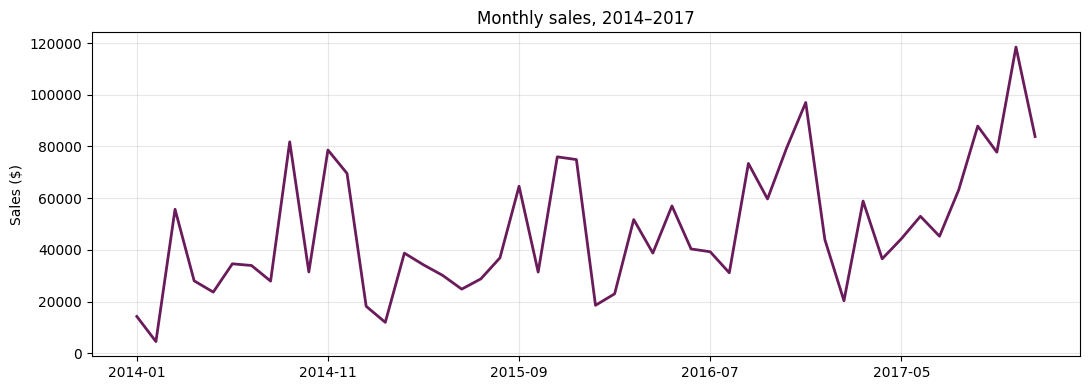

In [11]:
monthly = df.groupby("order_month")["sales"].sum()
ax = monthly.plot(figsize=(11, 4), color="#6A1B5A", linewidth=2)
ax.set_title("Monthly sales, 2014–2017"); ax.set_xlabel(""); ax.set_ylabel("Sales ($)")
ax.grid(alpha=.3); plt.tight_layout()
plt.savefig("../images/monthly_sales_trend.png", dpi=150); plt.show()

## 8. Export

In [12]:
df.to_csv(OUT, index=False, date_format="%Y-%m-%d", encoding="utf-8")
print(f"Saved {len(df):,} rows x {df.shape[1]} columns to {OUT}")

Saved 9,993 rows x 26 columns to ../data/processed/superstore_clean.csv
